EDA for the dataset 


In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("../data/train-test.csv")


In [3]:
df.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


The columns description is in \docs\DataDictionary.md

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


1-weight and MI not complete 

2-date is object dtype 


In [5]:
df.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


1-The weight has negative value 

2-the posted rate could have some outliers ,i must go deep 



In [6]:
df["equipment"].value_counts()

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

the syntax of the types  is perfect 

In [7]:
df["pickup"].nunique()

64

In [8]:
df["delivery"].nunique()

64

pickup has  64 cities, delivery has  64 cities

In [9]:
df["date"]=pd.to_datetime(df["date"])

changeing the date type to apply actions 

In [10]:
df["date"].describe()

count                         48000
mean     2025-05-31 19:53:29.400000
min             2025-01-01 00:00:00
25%             2025-03-18 00:00:00
50%             2025-05-31 00:00:00
75%             2025-08-15 00:00:00
max             2025-10-31 00:00:00
Name: date, dtype: object

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.duplicated(subset=["load_id"]).sum()

np.int64(0)

In [13]:
temp_df = df.drop(columns=["load_id"])

In [14]:
temp_df.duplicated().sum()

np.int64(0)

no dublicated values  at all in each possible case 



In [15]:
wrong_weights=df["weight"]<=0 
wrong_weights.sum()

np.int64(292)

weight: 292 negative values, 0 zeros.

In [16]:
df[df["weight"]<=0 ]

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,33.17137,-104.36789,39.87206,-85.62931,1334.2,Reefer,-36559.0,2025-01-01,0.96102,2.11777,2831.27
204,TR-000205,Fresno,Tucson,33.07921,-119.79528,30.92733,-113.23037,496.2,Dry Van,-26670.0,2025-01-02,0.96903,2.13155,1046.92
206,TR-000207,Columbia,Raleigh,34.63570,-83.28506,35.37376,-77.47605,411.3,Reefer,-20003.0,2025-01-02,0.94800,2.31682,959.15
225,TR-000226,Greensboro,Lubbock,35.98195,-82.78379,29.87534,-99.85456,1317.4,Reefer,-23981.0,2025-01-02,1.00820,2.13918,2836.00
376,TR-000377,Madison,Providence,41.70243,-89.85588,37.37287,-69.50000,1331.1,Dry Van,-41397.0,2025-01-03,0.94787,1.91867,2522.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47404,TR-047405,Baton Rouge,Memphis,30.50134,-92.65374,35.56802,-89.52871,468.7,Dry Van,-24142.0,2025-10-28,0.94219,1.83201,1077.64
47431,TR-047432,Phoenix,Chattanooga,28.75668,-115.87725,35.29792,-87.18651,1978.6,Flatbed,-35617.0,2025-10-28,0.92870,2.00708,4295.45
47735,TR-047736,Houston,Reno,30.71157,-94.76550,39.54838,-118.64843,1689.1,Reefer,-43951.0,2025-10-30,1.04615,1.85824,3933.12
47850,TR-047851,Shreveport,Cincinnati,32.54628,-92.31888,37.15706,-86.77499,538.3,Dry Van,-28144.0,2025-10-31,0.98093,1.86958,1191.61


In [17]:
df[df["weight"] <= 0]["weight"].describe()

count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64

In [18]:
df[df["weight"] > 0]["weight"].describe()

count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64

Assumed sign error because the values in negative is similar to positive 

In [19]:
(df["distance"]<=0).sum()

np.int64(0)

no negative or wrong in distance 

In [20]:
set(df["delivery"])== set(df["pickup"])

True

all of the 64 cities recorded  as pickup and delivery 

In [21]:
#here i just wana check if the coordinates is right in each possible case 
#case1:each city has unique coordinations in its columns 
#case2:the same coordinations are apply for both delivery and pickup 
print(df.groupby("pickup")["pickup_lat"].nunique().sum())
print(df.groupby("pickup")["pickup_lon"].nunique().sum())
print(df.groupby("delivery")["delivery_lon"].nunique().sum())
print(df.groupby("delivery")["delivery_lat"].nunique().sum())
pickup=df[["pickup","pickup_lat","pickup_lon"]] 
delivery=df[["delivery","delivery_lat","delivery_lon"]]
pickup=pickup.drop_duplicates()
delivery=delivery.drop_duplicates()
new_pickup=pickup.rename(
    columns={
        "pickup":"city",
        "pickup_lon":"lon",
        "pickup_lat":"lat"
    })
new_delivery=delivery.rename(
    columns={
        "delivery":"city",
        "delivery_lon":"lon",
        "delivery_lat":"lat",
    })
merger=new_delivery.merge(new_pickup)
merger.shape

64
64
64
64


(64, 3)

all of the cities has unique coordinations ,each city has one fixed lat/lon, same in pickup and delivery

In [22]:
(df["delivery"]== df["pickup"]).sum()

np.int64(0)

No loads where pickup == delivery

In [23]:
right_distance= df.groupby(["pickup", "delivery"])["distance"].nunique().max()
right_distance

np.int64(38)

one path has 38 diffrent distances,but we need to look deeper 

In [24]:
route_distance_counts = df.groupby(["pickup", "delivery"])["distance"].nunique()
worst_route = route_distance_counts.idxmax()
worst_route_df = df[(df["pickup"] == worst_route[0]) & (df["delivery"] == worst_route[1])]
worst_route_df["distance"].describe()

count     38.000000
mean     791.602632
std       14.048728
min      767.800000
25%      779.175000
50%      792.350000
75%      804.225000
max      813.700000
Name: distance, dtype: float64

Same route has slightly different distances ,normal variations 


In [25]:
df["rate_per_mile"] = df["posted_rate"] / df["distance"]
df["rate_per_mile"].describe()

count    48000.000000
mean         2.215347
std          0.583887
min          0.333709
25%          1.986974
50%          2.145348
75%          2.342696
max         14.125294
Name: rate_per_mile, dtype: float64

In [26]:
cols = ["pickup", "delivery", "distance", "equipment", "posted_rate", "rate_per_mile"]
print(df.sort_values("rate_per_mile")[cols].head(10))
print(df.sort_values("rate_per_mile", ascending=False)[cols].head(10))

               pickup      delivery  distance equipment  posted_rate  \
14102         Buffalo   Bakersfield    2536.4   Dry Van       846.42   
25798          Albany          Reno    2894.3   Dry Van       969.83   
23043         Phoenix  Philadelphia    2983.4   Dry Van      1047.91   
46173    Philadelphia       El Paso    2490.9   Dry Van       880.13   
508         Las Vegas  Grand Rapids    1976.4   Flatbed       699.41   
2511          Buffalo   San Antonio    1644.3   Flatbed       596.04   
40600      Fort Wayne       Phoenix    2210.6   Dry Van       808.74   
22458  Salt Lake City        Mobile    1632.3   Dry Van       599.77   
22464     Kansas City   Los Angeles    1909.1   Dry Van       709.46   
1555          El Paso      New York    2415.0   Dry Van       911.44   

       rate_per_mile  
14102       0.333709  
25798       0.335083  
23043       0.351247  
46173       0.353338  
508         0.353881  
2511        0.362489  
40600       0.365846  
22458       0.367439  


most loads are 2 - 2.3 $/mile, the extremes (0.33 and 14 $/mile) are far from normal

In [27]:
low = df[df["rate_per_mile"] < 1.4]
high = df[df["rate_per_mile"] > 4]
print(len(low), len(high))

337 340


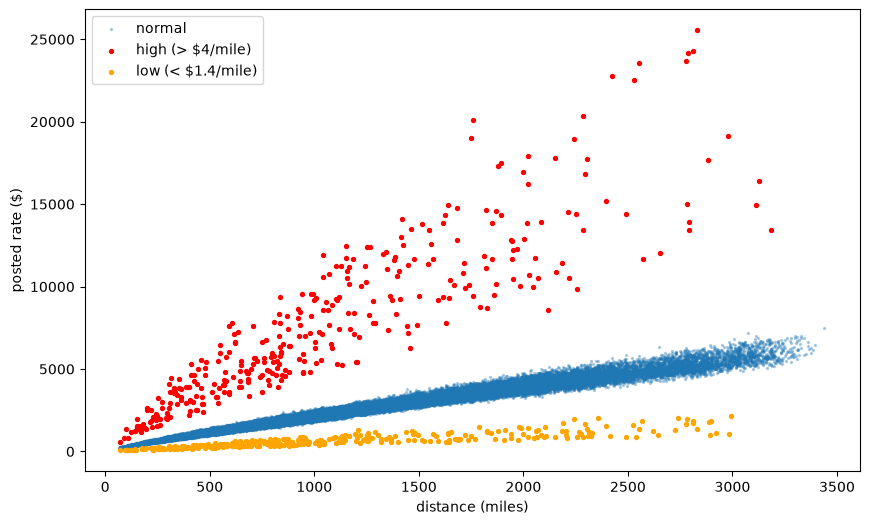

In [28]:
normal = df[(df["rate_per_mile"] >= 1.4) & (df["rate_per_mile"] <= 4)]

plt.figure(figsize=(10, 6))
plt.scatter(normal["distance"], normal["posted_rate"], s=2, alpha=0.3, label="normal")
plt.scatter(high["distance"], high["posted_rate"], s=8, color="red", label="high (> $4/mile)")
plt.scatter(low["distance"], low["posted_rate"], s=8, color="orange", label="low (< $1.4/mile)")
plt.xlabel("distance (miles)")
plt.ylabel("posted rate ($)")
plt.legend()
plt.show()


normal loads make a clear band, red points are far above and orange points far below 

In [29]:
df.select_dtypes("number").corr()["posted_rate"].sort_values(ascending=False)

posted_rate      1.000000
distance         0.908519
weight           0.034840
market_index     0.034165
rate_per_mile    0.003147
quote_signal    -0.039858
pickup_lat      -0.090873
delivery_lat    -0.091970
pickup_lon      -0.255058
delivery_lon    -0.257086
Name: posted_rate, dtype: float64

distance is by far the strongest relation with price (0.91), other columns are weak 

In [30]:
df["quote_ratio"] = df["rate_per_mile"] / df["quote_signal"]
close = (df["quote_ratio"] - 1).abs() < 0.03
close.groupby(df["date"].dt.month).mean()

date
1     0.977837
2     0.979709
3     0.979349
4     0.111019
5     0.102789
6     0.983274
7     0.096702
8     0.146669
9     0.982441
10    0.103029
Name: quote_ratio, dtype: float64

quote_signal equals the real rate per mile in months 1,2,3,6,9 (~98%) but not in other months (~10%) -> leakage and not reliable, i may drop it 

In [31]:
dec = pd.read_csv("../data/december-chart-inputs.csv")
dec.columns

Index(['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date',
       'predicted_rate'],
      dtype='object')

December file has no market_index, quote_signal or lat/lon -- lat/lon from city name (fixed per city), market_index: test with and without it later

In [32]:
val = pd.read_csv("../data/validation.csv", parse_dates=["date"])
print(val["date"].min(), val["date"].max())
print((val["weight"] <= 0).sum(), val["weight"].isna().sum())
print(set(val["pickup"]) - set(df["pickup"]))
print(set(val["delivery"]) - set(df["delivery"]))

2025-11-01 00:00:00 2025-12-31 00:00:00
145 165
{'Laredo', 'Knoxville', 'San Diego', 'Norfolk', 'Jackson', 'Charlotte', 'Allentown', 'Chicago'}
{'Knoxville', 'Laredo', 'San Diego', 'Norfolk', 'Jackson', 'Charlotte', 'Allentown', 'Chicago'}


validation is Nov-Dec 2025 (future), has 145 negative and 165 missing weights, and 8 new cities not in training 

In [33]:
ok = df[(df["rate_per_mile"] > 1.4) & (df["rate_per_mile"] < 4)]

print(ok.groupby("equipment")["rate_per_mile"].median())
print(ok.groupby(ok["date"].dt.month)["rate_per_mile"].median())
print(ok.groupby(ok["date"].dt.dayofweek)["rate_per_mile"].median())

equipment
Dry Van    2.045799
Flatbed    2.219689
Reefer     2.311990
Name: rate_per_mile, dtype: float64
date
1     2.029137
2     2.061119
3     2.139730
4     2.147233
5     2.190714
6     2.247064
7     2.186544
8     2.120555
9     2.158884
10    2.164207
Name: rate_per_mile, dtype: float64
date
0    2.126305
1    2.138568
2    2.161710
3    2.170516
4    2.158277
5    2.131785
6    2.127352
Name: rate_per_mile, dtype: float64


Reefer is ~13% more per mile than Dry Van, price rises Jan-Jun then drops a bit, mid-week is slightly higher (~2%) 